# 11 - Analysis of our own recording

We run the same analysis on a recording made by a team member.
The name of the recording is given with the variable MOUSE_FILE, read by the notebook 01_reading. Our two files are : 

- 002SaZo.csv: timestamp (ms), mouse position (x, y in pixels) and mouseInTarget (1 = inside the target, 0 = outside);
- 002SaZo.marker.csv: the events of the session (start and end of each record) and the table of results computed by MouseReMoCo.

The first 3 records are done with the right hand and the last 3 ones with the left hand.

## Chose the files to analyse

In [1]:
import os

# go to the project root (the notebook is in the "notebooks" folder)
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

# recording to analyse: name of the file without ".csv", in the data folder
os.environ["MOUSE_FILE"] = "002SaZo"

## Read the header

Below are the parameters of the task. They differ from the ones in the instruction because the task was not executed on the same computer. 

Contrary to the instructions, we do have 6 records usable.

In [2]:
%run notebooks/01_reading.ipynb

Header line information in 'data/002SaZo.csv':
  software: mouseReMoCo
  version: 1.3.0
  isWithLSL: false
  screenWidth: 1264.0
  screenHeight: 641.0
  centerX: 632.0
  centerY: 320.0
  autoStart: 3600.0
  cycleMaxNumber: 6.0
  cycleDuration: 20.0
  borderColor: java.awt.Color[r=255,g=255,b=255]
  textColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  task: circular
  cornerX: 392.0
  cornerY: 80.0
  externalRadius: 240.0
  internalRadius: 160.0
  borderRadius: 1.0
  cursorRadius: 16.0
  indexOfDifficulty: 26.670116357070796
  taskRadius: 199.5
  taskTolerance: 47.0
Same header in both files: True
Markers in 'data/002SaZo.marker.csv':
1793081857291: KeyTyped=32 ASCI=  DoCycleChange
1793081857291: DoCycleChange:DoStartCycleTimedSequence
1793081857291: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1793081877301: DoCycleChange:DoPause Recor

## Display the figures

The figures are displayed using the table result from 002SaZo.marker.csv.

- Figure 1: x and y over the whole session, with the start (black) and end (red) of each record.
- Figure 2: trajectory of the whole session, with the limits of the target.
- Figures 3 to 7: trajectory of each record, points inside (green) and outside (red) the target, with the screen (magenta) and the target ring (yellow).
- Figure 8: distance to the center (r) of each record over time, with the limits of the target.
- Figures 9 to 13: x, y and mouseInTarget of each record over time.

Main observations: in all the records the mouse is in the target in the beginning.
In record 0, the mouse is almost always in the target. For record 4 and 5, the mouse is often out of the target.

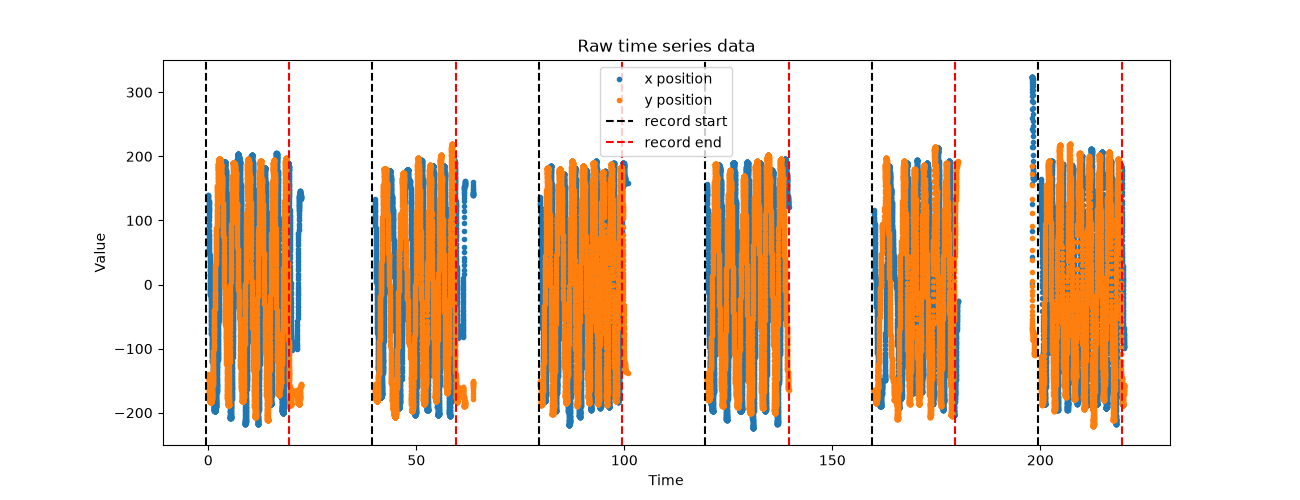

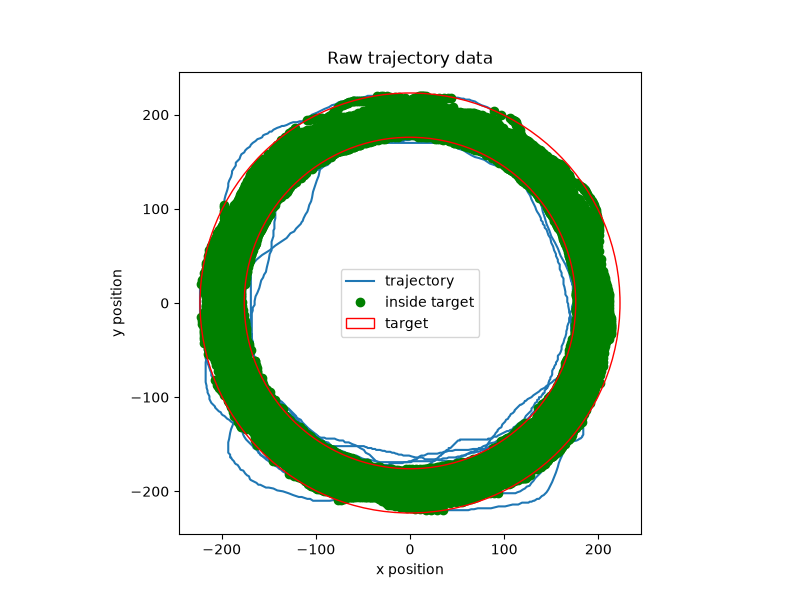

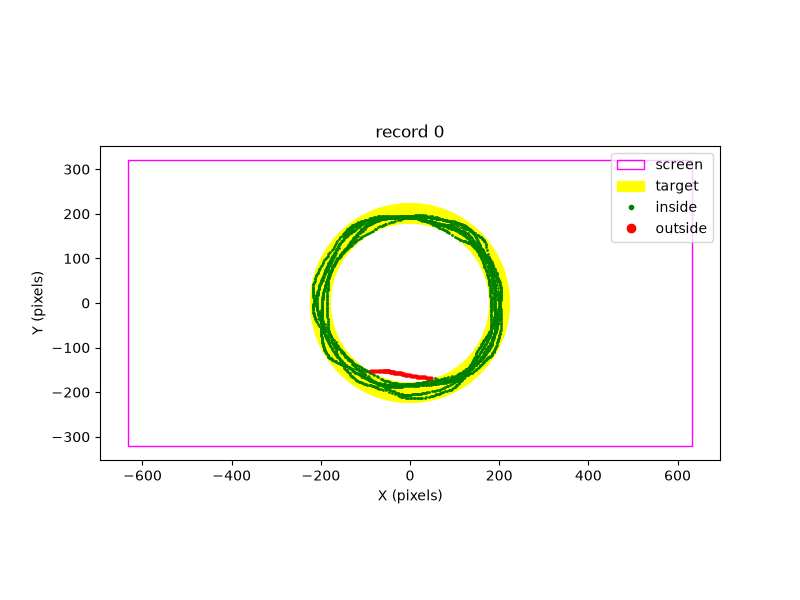

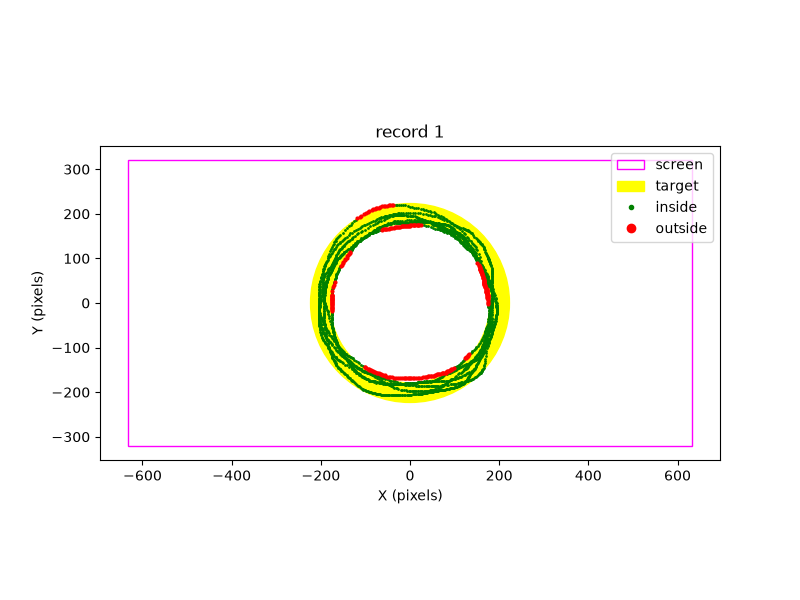

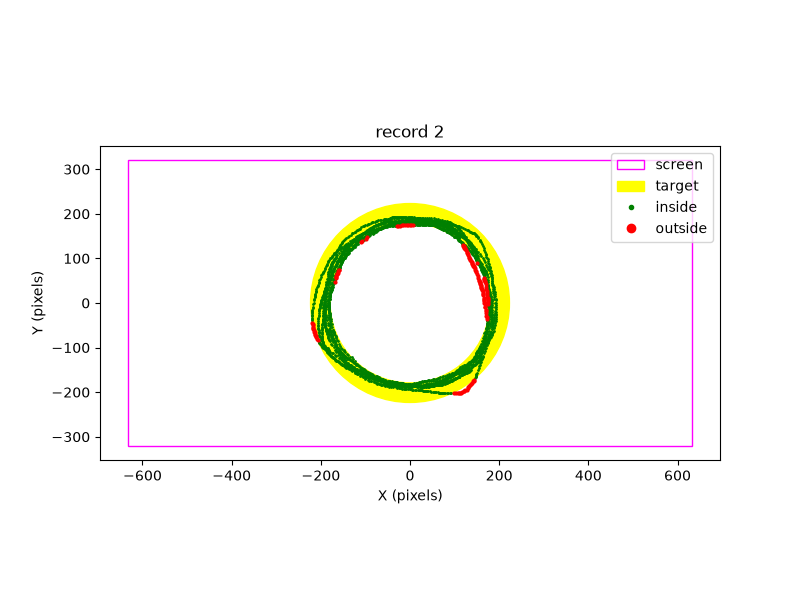

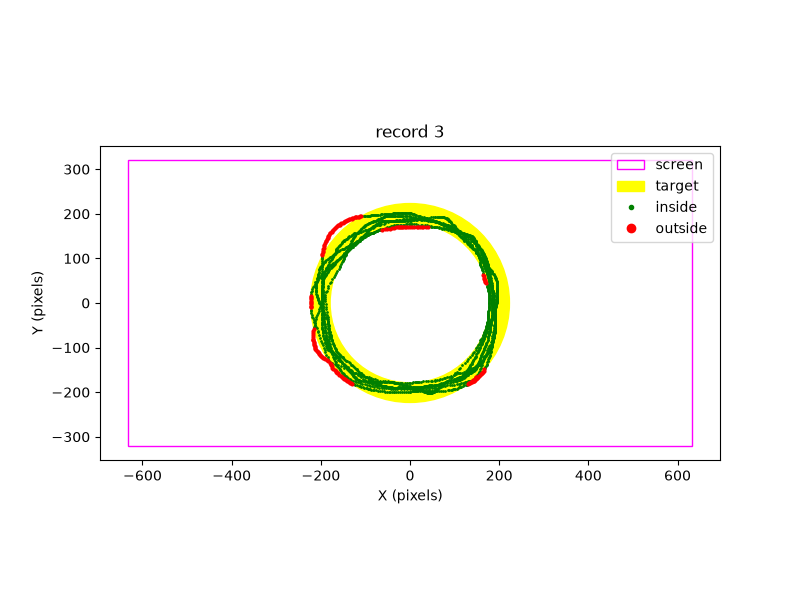

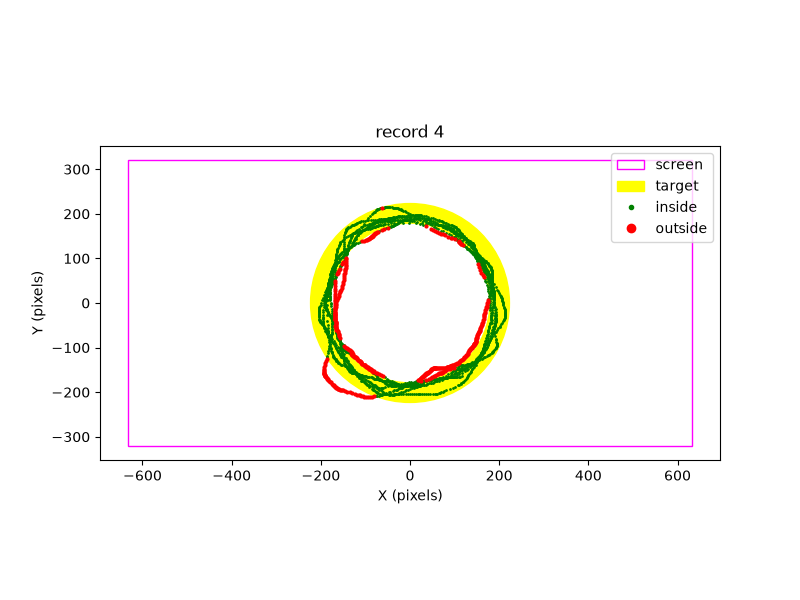

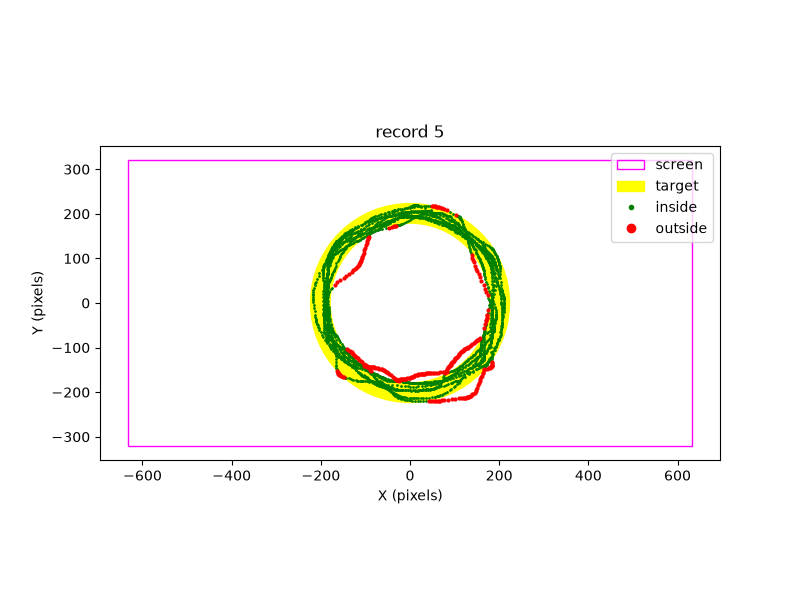

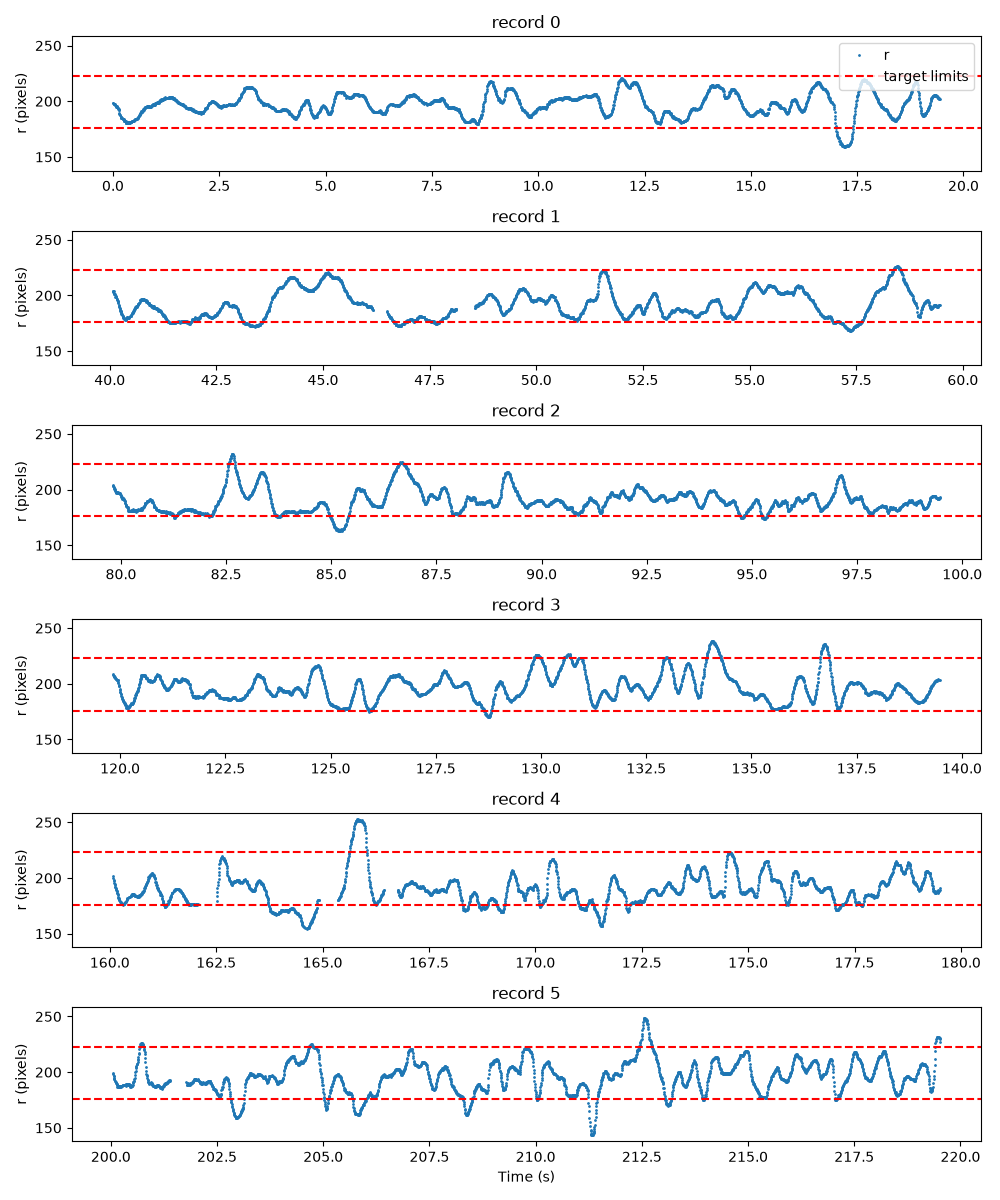

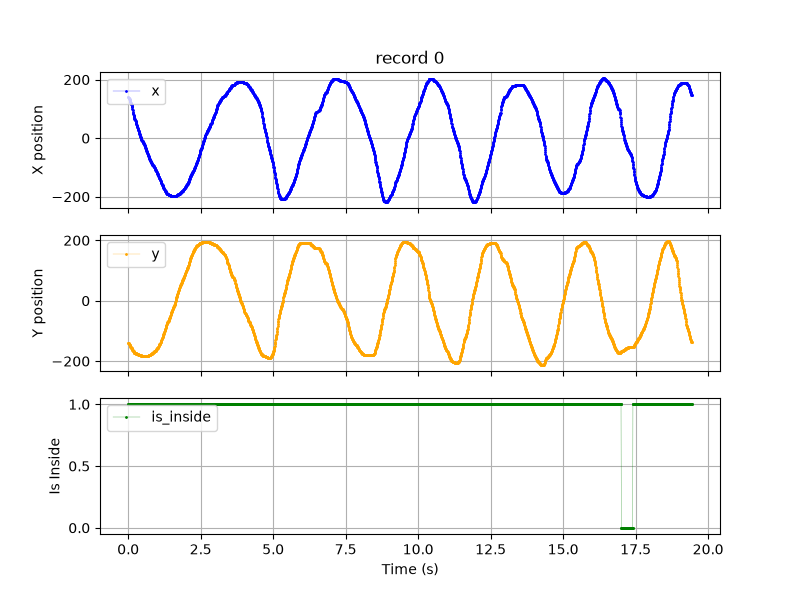

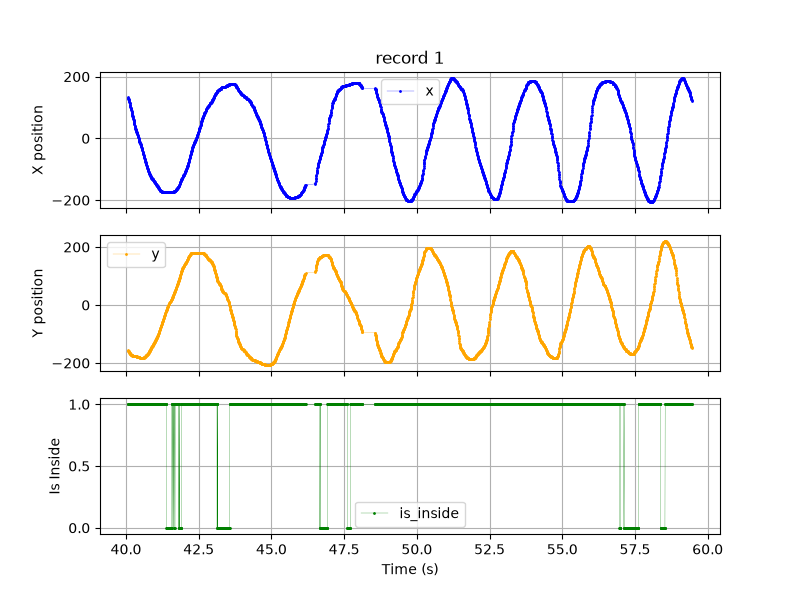

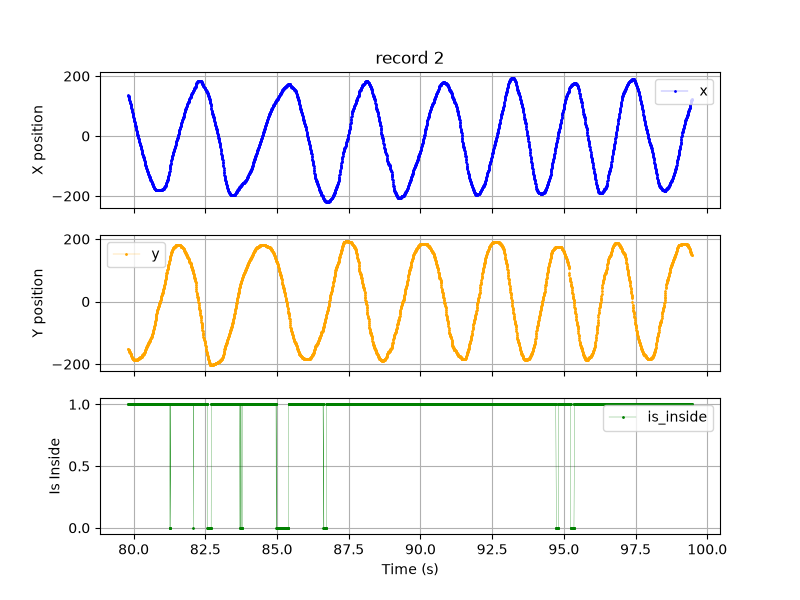

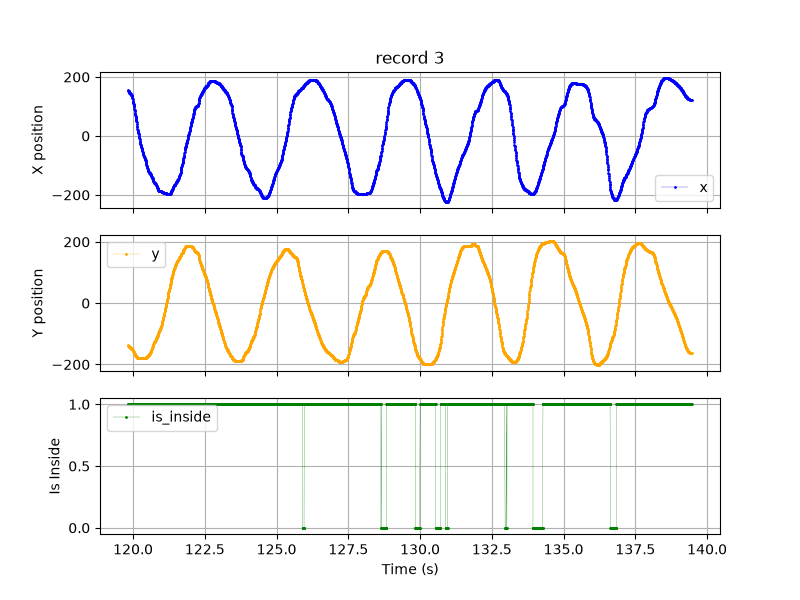

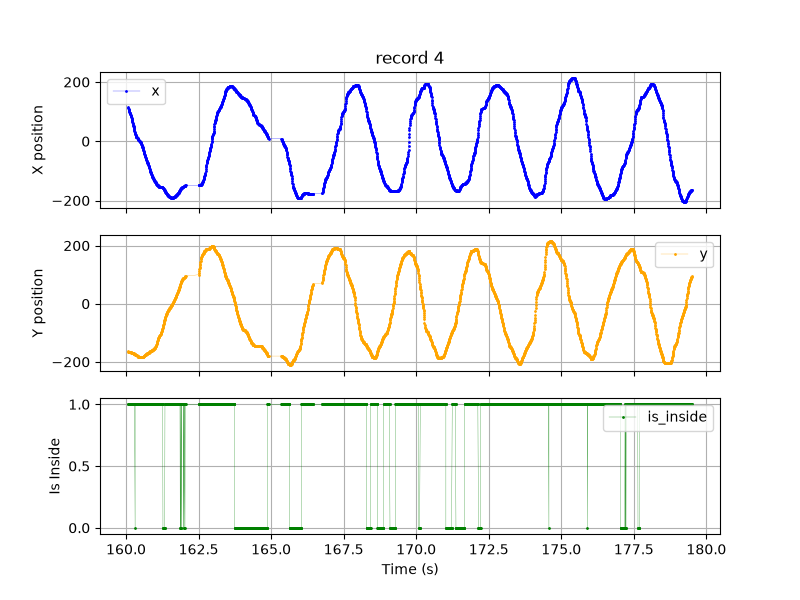

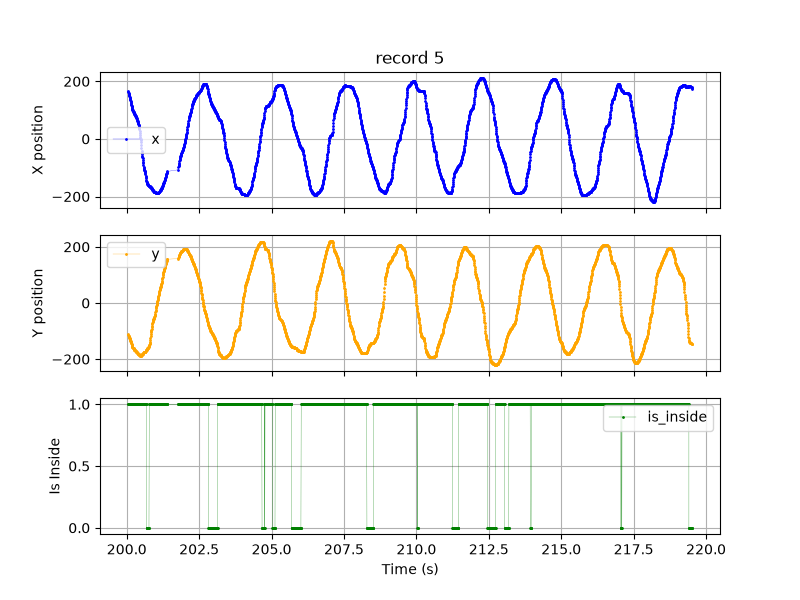

In [3]:
%run notebooks/02_graphics.ipynb

## Compute the values

Main results:
- the number of laps increases from record 0 to record 2. 6 laps are done in record 3 and 4, and 8 laps for record 5.
- Te is bigger for record 4 and 5, as well as the error.
- in records 0 and 2, Be is below 1 (0.91 to 0.93), in records 1,3 and 4 above 0 (1.12 to 1.32).
- IPe is bigger in record 2 (10.7 bit/s)

A summary table with all the values is printed at the end.

In [4]:
%run notebooks/03_computing.ipynb

record 0: first entry at   0.000 s (sample 0), 2778 samples kept
record 1: first entry at  40.075 s (sample 0), 2672 samples kept
record 2: first entry at  79.809 s (sample 0), 2858 samples kept
record 3: first entry at 119.830 s (sample 0), 2790 samples kept
record 4: first entry at 160.074 s (sample 0), 2589 samples kept
record 5: first entry at 200.050 s (sample 0), 2727 samples kept
record 0: nLaps =  -5.99
record 1: nLaps =  -6.00
record 2: nLaps =  -7.73
record 3: nLaps =  -6.03
record 4: nLaps =  -6.43
record 5: nLaps =  -8.02
record 0: Re = 197.27 px Te =  42.79 px error =   2.22 %
record 1: Re = 191.70 px Te =  52.59 px error =   8.84 %
record 2: Re = 189.99 px Te =  43.88 px error =   4.86 %
record 3: Re = 197.08 px Te =  52.71 px error =   6.32 %
record 4: Re = 190.00 px Te =  61.45 px error =  16.16 %
record 5: Re = 195.77 px Te =  61.92 px error =  10.47 %
record 0: MT/lap =  3.24 s/lap IDe/lap =  28.97 bit/lap Be =  0.91 IPe =   8.93 bit/s
record 1: MT/lap =  3.23 s/lap I

## Compare with the table fom MouseReCo

We read the table written by MouseReMoCo at the end of the marker file and compare it to our values.
For each variable, the largest difference between the two tables is printed.

In [5]:
%run notebooks/04_comparison.ipynb

nLaps   : max difference = 0.01
Re      : max difference = 0.01
Te      : max difference = 0.03
error   : max difference = 0.02
MT/lap  : max difference = 0.00
IDe/lap : max difference = 0.02
Be      : max difference = 0.00
IPe     : max difference = 0.01


## Conclusion

The larger difference is 0.03 for Te. This difference could be explain by rounding. Overall the values that we computed are closed to the one from the MouseReCo table.